## 6. Decision Trees and Ensemble Learning
This week, we'll talk about decision trees and tree-based ensemble algorithms. 

### 6.1 Credit risk scoring project
- Dataset: https://github.com/gastonstat/CreditScoring

In [2]:
import numpy as np 
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb

from IPython.display import display
import matplotlib.pyplot as plt
%matplotlib inline

### 6.2 Data cleaning and preparation
- Download the dataset
- Re-encoding the categorical variables
- Doing the train / validation / test split

In [3]:
df = pd.read_csv('CreditScoring.csv')

In [4]:
df.columns = df.columns.str.lower()

In [5]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


#### We have to preprocess the data as the github repo did

In [6]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

Using mapping func. to map `1 = ok`; `2 = default`, and `0 = unk` (unknown)

In [7]:
status_values = {1:'ok', 2:'default', 0:'unk'}
df.status = df.status.map(status_values)

In [8]:
home_values = {
    1: 'rent', 
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk',
}
df.home = df.home.map(home_values)

In [9]:
marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk',
}
df.marital = df.marital.map(marital_values)

In [10]:
records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk',
}
df.records = df.records.map(records_values)

In [11]:
job_values = {
    1: 'fixed',
    2: 'part_time',
    3: 'freelance',
    4: 'others',
    0: 'unk',
}
df.job = df.job.map(job_values)

In [12]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


in the dataset, NA is assigned as `99999999`, now we can deal with them:

In [13]:
for col in ['income', 'assets', 'debt']:
    
    df[col] =df[col].replace(to_replace=99999999, value=np.nan)

In [14]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [15]:
df = df[df.status != 'unk'].reset_index(drop=True)

Done!
Now we can apply `train_test_split` from sklearn. 

In [16]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)


In [17]:
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [18]:
y_train = (df_train.status == 'default').astype(int).values
y_val = (df_val.status == 'default').astype(int).values
y_test = (df_test.status == 'default').astype(int).values

In [19]:
del df_train['status']
del df_val['status']
del df_test['status']

### 6.3 Decision Trees
- How a decision tree looks like
- Training a decision tree
- Overfitting
- Controlling the size of a tree

In [20]:
# Simulating how decision tree works
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'part_time':
            return 'default'
        else:
            return 'ok'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'

In [21]:
xi = df_train.iloc[0].to_dict()

In [22]:
assess_risk(xi)

'ok'

The rules of Decision Tree can be learned from the data.

In [23]:
df_train

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,10,owner,36,36,married,no,freelance,75,0.0,10000.0,0.0,1000,1400
1,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330
2,1,parents,48,40,married,no,fixed,75,121.0,0.0,0.0,1320,1600
3,1,parents,48,23,single,no,part_time,35,72.0,0.0,0.0,1078,1079
4,5,owner,36,46,married,no,freelance,60,100.0,4000.0,0.0,1100,1897
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2667,18,private,36,45,married,no,fixed,45,220.0,20000.0,0.0,800,1600
2668,7,private,60,29,married,no,fixed,60,51.0,3500.0,500.0,1000,1290
2669,1,parents,24,19,single,no,fixed,35,28.0,0.0,0.0,400,600
2670,15,owner,48,43,married,no,freelance,60,100.0,18000.0,0.0,2500,2976


In [24]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

In [25]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [26]:
import sklearn
print(sklearn.__version__)         # 1.3 以上才支援
print(np.isnan(X_train).sum())     # X_train 裡有幾個 NaN, 原本有66個NaN

1.9.1
0


NOTE: Now some models in sklearn can run with NaN in the data, but always check NaN counts before running the model.

In [27]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [28]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [29]:
y_pred = dt.predict_proba(X_val)[:, 1]

#### Where does `predict_proba` come from in a Decision Tree?

A decision tree does **not** compute probabilities with a formula. Instead:

1. **Training:** the tree splits the training data until it reaches the leaves. Each leaf stores the **class distribution of the training samples** that ended up there.
2. **Prediction:** a new sample travels down the tree, following the split rules, until it lands in a leaf.
3. **Probability:** `predict_proba` returns the **proportion of each class in that leaf** (from the training set).

**Example:** if a leaf contained 30 `ok` and 10 `default` training samples, any new sample landing there gets `[0.75, 0.25]`.

**Notes:**
- The output has shape `(n_samples, n_classes)`. The column order follows `dt.classes_`, so use `y_pred[:, 1]` for the probability of class `1` (e.g. for `roc_auc_score`).
- With no depth limit, the tree grows until leaves are pure, so probabilities are mostly `0` or `1` → a sign of **overfitting**. Parameters like `max_depth` and `min_samples_leaf` keep more samples per leaf, giving smoother and more reliable probabilities.
- Other models differ: Random Forest **averages** the leaf proportions across trees; XGBoost **sums** tree scores and applies a sigmoid.

In [30]:
roc_auc_score(y_val, y_pred)

0.6624446005182727

In [31]:
y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

1.0

Ahhh, **OVERFITTING**, as we see.


Now, apply `max_depth = 3` in the model:

In [32]:
dt = DecisionTreeClassifier(max_depth=3)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [33]:
y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print('train', auc)

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print('val', auc)

train 0.7761016984958594
val 0.7389079944782155


In [34]:
print(export_text(dt, feature_names=dv.get_feature_names_out()))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- class: 0
|   |   |--- amount >  862.50
|   |   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- income <= 103.50
|   |   |   |--- class: 1
|   |   |--- income >  103.50
|   |   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=part_time <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- class: 0
|   |   |--- income >  74.50
|   |   |   |--- class: 0
|   |--- job=part_time >  0.50
|   |   |--- assets <= 8750.00
|   |   |   |--- class: 1
|   |   |--- assets >  8750.00
|   |   |   |--- class: 0



### 6.4 Decision Tree learning Algorithm
- Finding the best split for one column
- Finding the best split for the entire dataset
- Stopping criteria
- Decision tree learning algorithm

In [35]:
sample_data = [
    [8000, 'default'],
    [2000, 'default'],
    [0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]
df_example = pd.DataFrame(sample_data, columns=['assets', 'status'])

In [36]:
df_example.sort_values('assets')

,assets,status
2,0,default
1,2000,default
7,3000,default
5,4000,ok
3,5000,ok
4,5000,ok
0,8000,default
6,9000,ok


In [37]:
# Thresholds
Ts = [0, 2000, 3000, 4000, 5000, 8000]

In [38]:
for t in Ts:
    df_left = df_example[df_example.assets <= t]
    df_right = df_example[df_example.assets > t]
    print('Threshold = ', t)
    
    display(df_left)
    print(df_left.status.value_counts(normalize=True))
    display(df_right)
    print(df_right.status.value_counts(normalize=True))
    print()

Threshold =  0


,assets,status
2,0,default


status
default    1.0
Name: proportion, dtype: float64


,assets,status
0,8000,default
1,2000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

Threshold =  2000


,assets,status
1,2000,default
2,0,default


... (15 outputs left out)

,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
7,3000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64


,assets,status
6,9000,ok


status
ok    1.0
Name: proportion, dtype: float64



Now we can based on each threshold, compute the **Impurity** of left and right side, average them as the criteria:

|T|Decision Left|Impurity Left|Decision Right|Impurity Right|AVG|
|-|-|-|-|-|-|
|0|Default|0%|OK|93%|21%|
|0|Default|0%|OK|33%|16%|
|0|Default|0%|OK|20%|10%|
|0|Default|25%|OK|25%|25%|
|0|Default|50%|OK|50%|50%|
|0|Default|43%|OK|0%|21%|

Therefore, we should choose `T = 3000` which having the smallest average impurity.

----

Now adding another feature in the example:

In [39]:
sample_data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000, 500, 'ok'],
    [3000, 2000, 'default'],
]
df_example = pd.DataFrame(sample_data, columns=['assets', 'debt', 'status'])

In [40]:
df_example.sort_values('debt')

,assets,debt,status
6,9000,500,ok
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default
0,8000,3000,default


In [41]:
thresholds = {
    'assets': [0, 2000, 3000, 4000, 5000, 8000],
    'debt': [500, 1000, 2000],
}

In [42]:
for feature, Ts in thresholds.items():
    print(f'#{feature}')
    for t in Ts:
        df_left = df_example[df_example[feature] <= t]
        df_right = df_example[df_example[feature] > t]
        print('Threshold = ', t)
        
        display(df_left)
        print(df_left.status.value_counts(normalize=True))
        display(df_right)
        print(df_right.status.value_counts(normalize=True))
        print()
    print('#################')
    print('#################')

#assets
Threshold =  0


,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

Threshold =  2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default


... (27 outputs left out)

,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default


status
default    1.0
Name: proportion, dtype: float64

#################
#################


And draw the same table as we did with `assets`.

In short, `assets` is a better feature for splitting compared to `debt`.

**Finding the Best Split Algorithm:**

```python
for F in Features:
    # Find all thresholds for F
    for T in Thresholds:
        # Split dataset using 'F>T' condition
        # compute the impurity of the split

# Select the condition with the lowest (average) impurity, this will make two new nodes: left and right
# AND apply the same algorithm on the new nodes: left and right as the next depth of tree.
```

**Stopping Criteria**
- Group Already pure
- `max_depth`: Tree reached the max depth limit
- Group too small to split

----

##### 6.4 Short Summary - Decision Tree Learning Algorithm
- Find the best split
- Stop if `max_depth` is reached
- If left is sufficiently large:
    - and not pure:
    - `->` repeat for left
- If right is sufficiently large:
    - and not pure:
    - `->` repeat for right

### 6.5 Decision Trees parameter tuning
- selecting `max_depth`
- selecting `min_samples_leaf`

In [43]:
for d in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth = d)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print(f'd: {d} -> AUC: {auc:.3f}')

d: 1 -> AUC: 0.606
d: 2 -> AUC: 0.669
d: 3 -> AUC: 0.739
d: 4 -> AUC: 0.761
d: 5 -> AUC: 0.766
d: 6 -> AUC: 0.745
d: 10 -> AUC: 0.683
d: 15 -> AUC: 0.672
d: 20 -> AUC: 0.662
d: None -> AUC: 0.655


As we can see, the best `max_depth` is around `d = 4 or 5 or 6`.

In [44]:
scores = []
for d in [4, 5, 6, 7, 10, 15, 20, None]:
    for s in [1, 2, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth = d, min_samples_leaf=s)
        dt.fit(X_train, y_train)
        
        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        # print(f'd = {d} | s = {s} -> AUC: {auc:.3f}')
        scores.append((d, s, auc))

In [45]:
df_scores = pd.DataFrame(scores, columns = ['max_depth', 'min_samples_leaf', 'AUC'])
df_scores.sort_values('AUC', ascending=False).head()

,max_depth,min_samples_leaf,AUC
40,10.0,15,0.791071
67,NaN,15,0.788120
49,15.0,15,0.788068
58,20.0,15,0.786782
22,6.0,15,0.785319


In [46]:
df_scores_pivot = df_scores.pivot(index="min_samples_leaf", columns="max_depth", values="AUC")

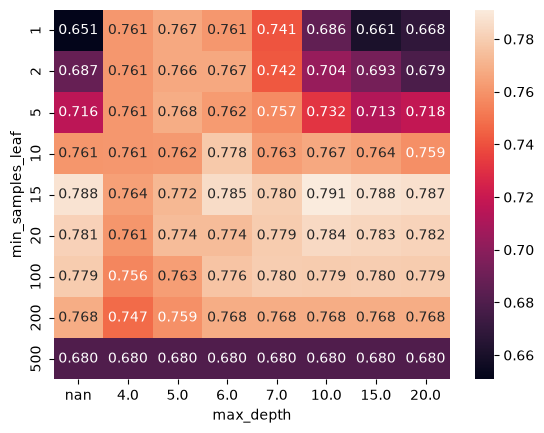

In [47]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f');

According to the heatmap, we'll choose `max_depth = 6` with `min_samples_leaf = 15`, though the AUC is not the best / largest, it is **good enough** with the simpler model, in order to maintain good generalization on unseen data and reduce the risk of overfitting.

### 6.6 Ensembles and random forest
- Board of experts
- Ensembling models
- Random forest - ensembling decision trees
- Tuning random forest

#### Random Forest

Random Forest is an **ensemble** of decision trees. A single decision tree tends to overfit (high variance), so we train many trees and combine their predictions.

If all trees were identical, combining them would not help. Random Forest makes the trees **different** with two sources of randomness:

1. **Bootstrap sampling (bagging):** each tree is trained on a random sample of the training data, drawn **with replacement**.
2. **Random feature subsets:** at **each split**, a tree only considers a random subset of features (`max_features`, default `sqrt` for classification).

Each tree makes its own prediction, and the forest **averages the `predict_proba` of all trees** to get the final probability.

Because the trees make different errors, averaging them cancels out much of the noise. This **reduces variance** and helps the model **generalize better** than a single tree.

In [48]:
rf = RandomForestClassifier(n_estimators = 10, random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [49]:
y_pred = rf.predict_proba(X_val)[:, 1]

In [50]:
roc_auc_score(y_val, y_pred)

0.7744726453706618

In [51]:
scores = []
for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators = n, random_state=1)
    rf.fit(X_train, y_train)
    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append((n, auc))

In [52]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'AUC'])

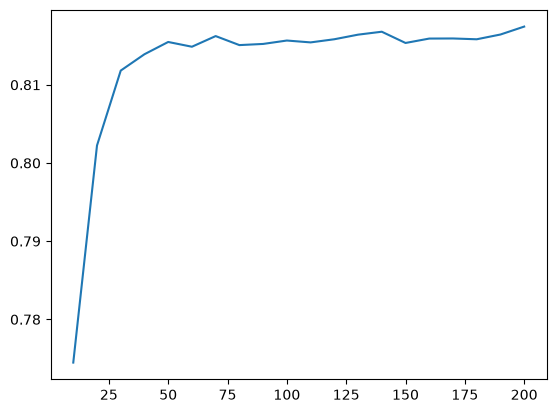

In [53]:
plt.plot(df_scores.n_estimators, df_scores.AUC);

As we can see, the `AUC` drastically increased until `n_estimators` hit 50.

In [54]:
scores = []
for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators = n,
                                    max_depth = d,
                                    random_state=1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d, n, auc))

In [55]:
df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'AUC'])
df_scores.head()

,max_depth,n_estimators,AUC
0,5,10,0.787699
1,5,20,0.797731
2,5,30,0.800305
3,5,40,0.799708
4,5,50,0.799878


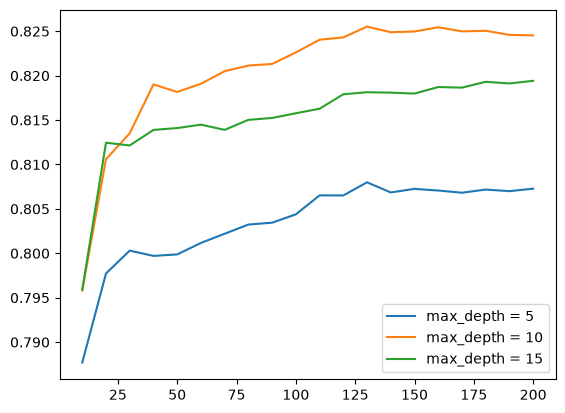

In [56]:
for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.AUC, label = f'max_depth = {d}')
plt.legend();

According to the plot above, `max_depth = 10` and `n_estimator = 130` can reach the highest `AUC`.

Now we choose `max_depth = 10` and then find the best / good enough value of `min_samples_leaf`:

In [57]:
scores = []
max_depth = 10
for d in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators = n,
                                    max_depth = max_depth,
                                    min_samples_leaf=d,
                                    random_state=1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d, n, auc))

In [58]:
df_scores = pd.DataFrame(scores, columns=['min_samples_leaf', 'n_estimators', 'AUC'])
df_scores.head()

,min_samples_leaf,n_estimators,AUC
0,1,10,0.795818
1,1,20,0.810597
2,1,30,0.813510
3,1,40,0.819013
4,1,50,0.818160


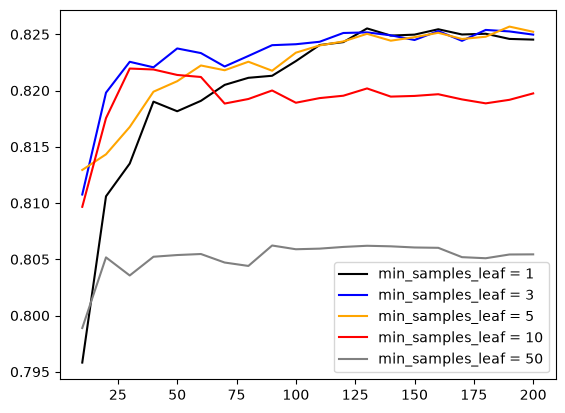

In [59]:
colors = ['black', 'blue', 'orange', 'red', 'grey']
samples = [1, 3, 5, 10, 50]
for d, col in zip(samples, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == d]
    plt.plot(df_subset.n_estimators, df_subset.AUC, label = f'min_samples_leaf = {d}',
            color = col)
plt.legend();

`min_samples_leaf = 1 or 3 or 5` can achieve high AUC, now we choose `min_samples_leaf = 3`

In [60]:
min_samples = 3

Now our final model would be:

In [61]:
rf = RandomForestClassifier(n_estimators = n,
                                    max_depth = 10,
                                    min_samples_leaf=3,
                                    random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

Other useful parameters:
- `max_features`
- `bootstrap`

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

### 6.7 Gradient Boosting and XGBoost
- Gradient Boosting vs Random Forest
- Installing XGBoost
- Training the first model
- Performance monitoring
- Parsing XGBoost's monitoring output

In [62]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label = y_train, feature_names = features)
dval = xgb.DMatrix(X_val, label = y_val, feature_names = features)

In [63]:
xgb_params = {
    'eta': 0.3,         # learning rate
    'max_depth': 6,     # same as Random Forest
    'min_child_weight': 1, # a bit similar as min_samples_leaf in RF
    
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}
model = xgb.train(xgb_params, dtrain, num_boost_round = 200)

In [64]:
y_pred = model.predict(dval)

In [65]:
roc_auc_score(y_val, y_pred)

0.8045064299726334

----

In [66]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [67]:
xgb_params = {
    'eta': 0.3,         # learning rate
    'max_depth': 6,     # same as Random Forest
    'min_child_weight': 1, # a bit similar as min_samples_leaf in RF
    'eval_metric': 'auc',
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}
model = xgb.train(xgb_params, dtrain, evals = watchlist, num_boost_round = 200, verbose_eval=5)

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.93359	val-auc:0.81150
[10]	train-auc:0.95391	val-auc:0.82002
[15]	train-auc:0.97087	val-auc:0.82220
[20]	train-auc:0.97677	val-auc:0.82239
[25]	train-auc:0.98440	val-auc:0.82074
[30]	train-auc:0.98805	val-auc:0.82061
[35]	train-auc:0.99239	val-auc:0.81804
[40]	train-auc:0.99474	val-auc:0.81732
[45]	train-auc:0.99627	val-auc:0.81413
[50]	train-auc:0.99753	val-auc:0.81320
[55]	train-auc:0.99811	val-auc:0.81140
[60]	train-auc:0.99893	val-auc:0.80818
[65]	train-auc:0.99924	val-auc:0.80696
[70]	train-auc:0.99955	val-auc:0.80710
[75]	train-auc:0.99979	val-auc:0.80802
[80]	train-auc:0.99987	val-auc:0.80813
[85]	train-auc:0.99993	val-auc:0.80761
[90]	train-auc:0.99995	val-auc:0.80782
[95]	train-auc:0.99997	val-auc:0.80870
[100]	train-auc:0.99999	val-auc:0.80839
[105]	train-auc:1.00000	val-auc:0.80735
[110]	train-auc:1.00000	val-auc:0.80730
[115]	train-auc:1.00000	val-auc:0.80779
[120]	train-auc:1.00000	val-auc:0.80570
[125]	train-auc:1.0000

Here in the lesson, `%%capture output` was used, in order to assign logs to `output`.

But we can use `eval_result` argument in `xgb.train()`:

In [68]:
xgb_params = {
    'eta': 0.3,         # learning rate
    'max_depth': 6,     # same as Random Forest
    'min_child_weight': 1, # a bit similar as min_samples_leaf in RF
    'eval_metric': 'auc',
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}
eval_result = {}
# {'train': {'auc': [0.86632, 0.89..., ...]},
#  'val':   {'auc': [0.77998, 0.79..., ...]}}
model = xgb.train(
                xgb_params,
                dtrain,
                evals = watchlist,
                num_boost_round = 200,
                verbose_eval=5,
                evals_result = eval_result
                )
df_eval = pd.DataFrame({
    'train_auc': eval_result['train']['auc'],
    'val_auc': eval_result['val']['auc'],
})

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.93359	val-auc:0.81150
[10]	train-auc:0.95391	val-auc:0.82002
[15]	train-auc:0.97087	val-auc:0.82220
[20]	train-auc:0.97677	val-auc:0.82239
[25]	train-auc:0.98440	val-auc:0.82074
[30]	train-auc:0.98805	val-auc:0.82061
[35]	train-auc:0.99239	val-auc:0.81804
[40]	train-auc:0.99474	val-auc:0.81732
[45]	train-auc:0.99627	val-auc:0.81413
[50]	train-auc:0.99753	val-auc:0.81320
[55]	train-auc:0.99811	val-auc:0.81140
[60]	train-auc:0.99893	val-auc:0.80818
[65]	train-auc:0.99924	val-auc:0.80696
[70]	train-auc:0.99955	val-auc:0.80710
[75]	train-auc:0.99979	val-auc:0.80802
[80]	train-auc:0.99987	val-auc:0.80813
[85]	train-auc:0.99993	val-auc:0.80761
[90]	train-auc:0.99995	val-auc:0.80782
[95]	train-auc:0.99997	val-auc:0.80870
[100]	train-auc:0.99999	val-auc:0.80839
[105]	train-auc:1.00000	val-auc:0.80735
[110]	train-auc:1.00000	val-auc:0.80730
[115]	train-auc:1.00000	val-auc:0.80779
[120]	train-auc:1.00000	val-auc:0.80570
[125]	train-auc:1.0000

In [69]:
df_eval.head(25)

,train_auc,val_auc
0,0.866320,0.779979
1,0.890769,0.790193
2,0.905009,0.788498
3,0.915396,0.799738
4,0.923793,0.802993
5,0.933595,0.811496
6,0.937846,0.811339
7,0.943328,0.812302
8,0.948055,0.811802
9,0.951123,0.815626


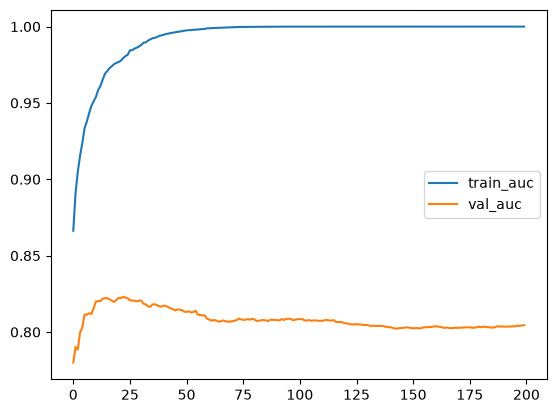

In [70]:
plt.plot(df_eval.train_auc, label = 'train_auc')
plt.plot(df_eval.val_auc, label = 'val_auc')
plt.legend()

### 6.8 XGBoost parameter tuning
Tuning the following parameters:
- `eta`
- `max_depth`
- `min_child_weight`

In [71]:
scores = {}

In [72]:
#tuning eta first:
xgb_params = {
    'eta': 0.01,         # learning rate
    'max_depth': 6,     # same as Random Forest
    'min_child_weight': 1, # a bit similar as min_samples_leaf in RF
    'eval_metric': 'auc',
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}
eval_result = {}
# {'train': {'auc': [0.86632, 0.89..., ...]},
#  'val':   {'auc': [0.77998, 0.79..., ...]}}
model = xgb.train(
                xgb_params,
                dtrain,
                evals = watchlist,
                num_boost_round = 200,
                verbose_eval=5,
                evals_result = eval_result
                )
df_eval = pd.DataFrame({
    'train_auc': eval_result['train']['auc'],
    'val_auc': eval_result['val']['auc'],
})

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.87007	val-auc:0.77821
[10]	train-auc:0.87208	val-auc:0.77838
[15]	train-auc:0.87381	val-auc:0.78277
[20]	train-auc:0.87584	val-auc:0.78719
[25]	train-auc:0.88595	val-auc:0.79571
[30]	train-auc:0.89329	val-auc:0.80000
[35]	train-auc:0.89642	val-auc:0.79971
[40]	train-auc:0.89881	val-auc:0.79866
[45]	train-auc:0.90066	val-auc:0.79690
[50]	train-auc:0.90259	val-auc:0.79705
[55]	train-auc:0.90401	val-auc:0.79737
[60]	train-auc:0.90552	val-auc:0.79690
[65]	train-auc:0.90670	val-auc:0.79633
[70]	train-auc:0.90816	val-auc:0.79749
[75]	train-auc:0.90974	val-auc:0.79862
[80]	train-auc:0.91118	val-auc:0.79924
[85]	train-auc:0.91239	val-auc:0.80075
[90]	train-auc:0.91393	val-auc:0.80254
[95]	train-auc:0.91541	val-auc:0.80339
[100]	train-auc:0.91684	val-auc:0.80390
[105]	train-auc:0.91797	val-auc:0.80428
[110]	train-auc:0.91933	val-auc:0.80442
[115]	train-auc:0.92046	val-auc:0.80430
[120]	train-auc:0.92178	val-auc:0.80471
[125]	train-auc:0.9231

In [73]:
key = f'eta={xgb_params['eta']}'
scores[key] = df_eval

In [74]:
scores.keys()

dict_keys(['eta=0.01'])

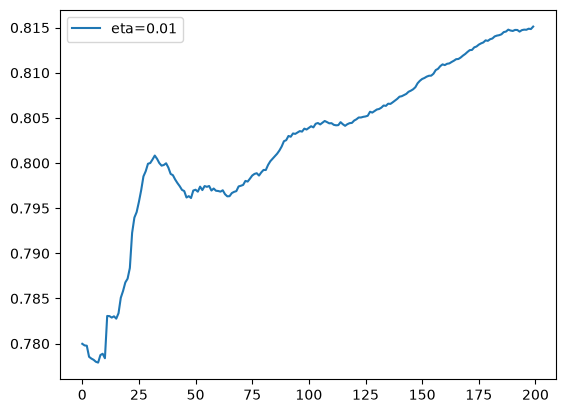

In [75]:
for key, df_scores in scores.items():
    plt.plot(df_scores.val_auc, label = key)
plt.legend();

In [76]:
# tune the max_depth
xgb_params = {
    'eta': 0.1,         # learning rate
    'max_depth': 4,     # same as Random Forest
    'min_child_weight': 1, # a bit similar as min_samples_leaf in RF
    'eval_metric': 'auc',
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}
eval_result = {}
# {'train': {'auc': [0.86632, 0.89..., ...]},
#  'val':   {'auc': [0.77998, 0.79..., ...]}}
model = xgb.train(
                xgb_params,
                dtrain,
                evals = watchlist,
                num_boost_round = 200,
                verbose_eval=5,
                evals_result = eval_result
                )
df_eval = pd.DataFrame({
    'train_auc': eval_result['train']['auc'],
    'val_auc': eval_result['val']['auc'],
})

[0]	train-auc:0.81665	val-auc:0.76001
[5]	train-auc:0.85305	val-auc:0.79139
[10]	train-auc:0.86708	val-auc:0.80281
[15]	train-auc:0.88086	val-auc:0.80892
[20]	train-auc:0.89073	val-auc:0.81369
[25]	train-auc:0.89725	val-auc:0.81674
[30]	train-auc:0.90358	val-auc:0.81858
[35]	train-auc:0.90984	val-auc:0.81931
[40]	train-auc:0.91390	val-auc:0.82153
[45]	train-auc:0.91872	val-auc:0.82206
[50]	train-auc:0.92192	val-auc:0.82412
[55]	train-auc:0.92575	val-auc:0.82386
[60]	train-auc:0.92873	val-auc:0.82430
[65]	train-auc:0.93138	val-auc:0.82604
[70]	train-auc:0.93407	val-auc:0.82626
[75]	train-auc:0.93679	val-auc:0.82579
[80]	train-auc:0.93913	val-auc:0.82577
[85]	train-auc:0.94131	val-auc:0.82536
[90]	train-auc:0.94360	val-auc:0.82700
[95]	train-auc:0.94580	val-auc:0.82828
[100]	train-auc:0.94764	val-auc:0.82851
[105]	train-auc:0.94958	val-auc:0.82817
[110]	train-auc:0.95164	val-auc:0.82782
[115]	train-auc:0.95334	val-auc:0.82828
[120]	train-auc:0.95469	val-auc:0.82797
[125]	train-auc:0.9556

In [77]:
key = f'max_depth={xgb_params['max_depth']}'
scores[key] = df_eval

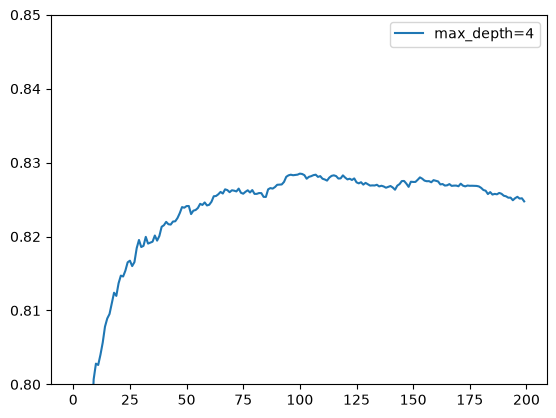

In [78]:
for max_depth, df_scores in scores.items():
    if max_depth[0] != 'e' and max_depth != 'max_depth=10':
        plt.plot(df_scores.val_auc, label = max_depth)
plt.ylim((0.8, 0.85))
plt.legend();

We could choose `max_depth = 3` for the best AUC.

In [79]:
# tune the min_child_weight:
xgb_params = {
    'eta': 0.1,         # learning rate
    'max_depth': 3,     # same as Random Forest
    'min_child_weight': 30, # a bit similar as min_samples_leaf in RF
    'eval_metric': 'auc',
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}
eval_result = {}
# {'train': {'auc': [0.86632, 0.89..., ...]},
#  'val':   {'auc': [0.77998, 0.79..., ...]}}
model = xgb.train(
                xgb_params,
                dtrain,
                evals = watchlist,
                num_boost_round = 200,
                verbose_eval=5,
                evals_result = eval_result
                )
df_eval = pd.DataFrame({
    'train_auc': eval_result['train']['auc'],
    'val_auc': eval_result['val']['auc'],
})

[0]	train-auc:0.76455	val-auc:0.73369
[5]	train-auc:0.82726	val-auc:0.77541
[10]	train-auc:0.84490	val-auc:0.79367
[15]	train-auc:0.85494	val-auc:0.80348
[20]	train-auc:0.86212	val-auc:0.81104
[25]	train-auc:0.86845	val-auc:0.81501
[30]	train-auc:0.87142	val-auc:0.81779
[35]	train-auc:0.87368	val-auc:0.82067
[40]	train-auc:0.87736	val-auc:0.82399
[45]	train-auc:0.87919	val-auc:0.82441
[50]	train-auc:0.88194	val-auc:0.82715
[55]	train-auc:0.88292	val-auc:0.82813
[60]	train-auc:0.88469	val-auc:0.82954
[65]	train-auc:0.88587	val-auc:0.83019
[70]	train-auc:0.88737	val-auc:0.83130
[75]	train-auc:0.88840	val-auc:0.83202
[80]	train-auc:0.88931	val-auc:0.83256
[85]	train-auc:0.89051	val-auc:0.83281
[90]	train-auc:0.89150	val-auc:0.83428
[95]	train-auc:0.89231	val-auc:0.83409
[100]	train-auc:0.89286	val-auc:0.83460
[105]	train-auc:0.89363	val-auc:0.83520
[110]	train-auc:0.89448	val-auc:0.83524
[115]	train-auc:0.89508	val-auc:0.83558
[120]	train-auc:0.89575	val-auc:0.83585
[125]	train-auc:0.8963

In [80]:
key = f'min_child_weight={xgb_params['min_child_weight']}'
scores[key] = df_eval

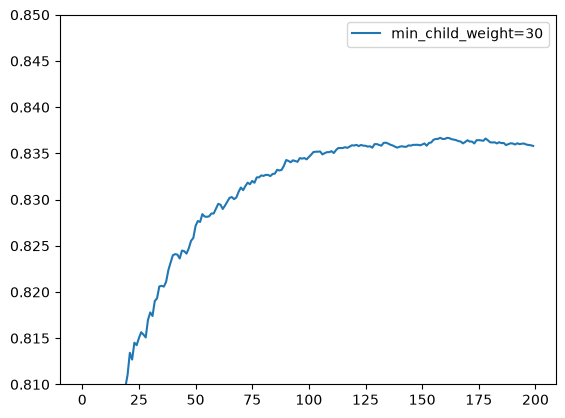

In [81]:
for max_depth, df_scores in scores.items():
    if max_depth[0] != 'e' and 'max' not in max_depth:
        plt.plot(df_scores.val_auc, label = max_depth)
plt.ylim((0.81, 0.85))
plt.legend();

As we see, the differences of AUC of each different setting of min_child_weight is pretty negligible. Therefore we may choose the simpler one: `min_child_weight = 1` for the model


Other parameters: https://xgboost.readthedocs.io/en/stable/python/python_intro.html#setting-parameters

Useful ones:
- `subsample` and `colsample_bytree`
- `lambda` and `alpha`

### 6.9 Selecting the final model
- Choosing between XGBoost, Random Forest, and Decision Tree
- Training the final model
- Saving the model

In [82]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [83]:
y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7848562640769174

In [84]:
rf = RandomForestClassifier(n_estimators = 200,
                                    max_depth = 10,
                                    min_samples_leaf=3,
                                    random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [85]:
y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8249709379767989

In [86]:
# tune the min_child_weight:
xgb_params = {
    'eta': 0.1,         # learning rate
    'max_depth': 3,     # same as Random Forest
    'min_child_weight': 1, # a bit similar as min_samples_leaf in RF
    'eval_metric': 'auc',
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}
eval_result = {}
# {'train': {'auc': [0.86632, 0.89..., ...]},
#  'val':   {'auc': [0.77998, 0.79..., ...]}}
model = xgb.train(
                xgb_params,
                dtrain,
                evals = watchlist,
                num_boost_round = 200,
                verbose_eval=5,
                evals_result = eval_result
                )

[0]	train-auc:0.77610	val-auc:0.73891
[5]	train-auc:0.83148	val-auc:0.77512
[10]	train-auc:0.84959	val-auc:0.79036
[15]	train-auc:0.86042	val-auc:0.80374
[20]	train-auc:0.86923	val-auc:0.81200
[25]	train-auc:0.87551	val-auc:0.81434
[30]	train-auc:0.88150	val-auc:0.81779
[35]	train-auc:0.88589	val-auc:0.82108
[40]	train-auc:0.88999	val-auc:0.82309
[45]	train-auc:0.89370	val-auc:0.82460
[50]	train-auc:0.89730	val-auc:0.82573
[55]	train-auc:0.90073	val-auc:0.82642
[60]	train-auc:0.90342	val-auc:0.82734
[65]	train-auc:0.90582	val-auc:0.82800
[70]	train-auc:0.90811	val-auc:0.82908
[75]	train-auc:0.91057	val-auc:0.82988
[80]	train-auc:0.91225	val-auc:0.83058
[85]	train-auc:0.91457	val-auc:0.83155
[90]	train-auc:0.91632	val-auc:0.83169
[95]	train-auc:0.91797	val-auc:0.83157
[100]	train-auc:0.91970	val-auc:0.83241
[105]	train-auc:0.92157	val-auc:0.83318
[110]	train-auc:0.92274	val-auc:0.83314
[115]	train-auc:0.92405	val-auc:0.83322
[120]	train-auc:0.92535	val-auc:0.83337
[125]	train-auc:0.9271

In [87]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8343918771645153

Next, apply the best model on `df_full_train`:

In [88]:
df_full_train = df_full_train.reset_index(drop = True)

In [89]:
y_full_train = (df_full_train.status == 'default').astype(int).values

In [90]:
y_full_train

array([0, 1, 0, ..., 0, 0, 1], shape=(3563,))

In [91]:
del df_full_train['status']

In [93]:
dict_full_train = df_full_train.to_dict(orient = 'records')

dv = DictVectorizer(sparse = False)
X_full_train = dv.fit_transform(dict_full_train)

dict_test = df_test.to_dict(orient = 'records')
X_test = dv.transform(dict_test)

In [95]:
dfulltrain = xgb.DMatrix(X_full_train, label = y_full_train,
                        feature_names = list(dv.get_feature_names_out()))
dtest = xgb.DMatrix(X_test,
                    feature_names = list(dv.get_feature_names_out()))

In [96]:
xgb_params = {
    'eta': 0.1,         # learning rate
    'max_depth': 3,     # same as Random Forest
    'min_child_weight': 1, # a bit similar as min_samples_leaf in RF
    'eval_metric': 'auc',
    'objective': 'binary:logistic',
    
    'nthread': 8,
    'seed': 1, 
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round = 175)

In [97]:
y_pred = model.predict(dtest)

In [98]:
roc_auc_score(y_test, y_pred)

0.8290589414007137

### 6.10 Summary
- Decision trees learn if-then-else rules from data. 
- Finding the best split: Select the least impure split. This algorithm can overfit, that's why we control it by limiting the `max_depth` and the size of the group.
- Random Forest is a way of combining multiple decision trees. It should have a diverse set of models to make good predictions. 
- Gradient boosting trains model sequentially: each model tries to fix errors of the previous model. XGBoost is an implementation of gradient boosting.

### 6.11 Explore More
- For this Data set we did do EDA or feature engineering. You can do it to get more insights into the problem.
- For Random Forest, there are more parameters that we can tune. Check `max_features` and `bootstrap`.
- There's a variation of random forest called **"Extremely Randomized Trees"**, or "Extra trees". Instead of selecting the best split among them. Because of that extra trees never overfit. In Scikit-Learn, they are implemented in `ExtraTreesClassifier`. Try it for this project.
- XGBoost can deal with NAs - we don't have to do `fillna` for it. Check if not filling NA's help improve performance.
- Experiment with other XGBoost parameters: `subsmaple` and `colsample_bytree`.
- When selecting the best split, decision trees find the most useful features. This information can be used for understanding which features are more important than others. See example here for [random forest](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html) (it's the same for plan decision trees) and for [xgboost](https://stackoverflow.com/questions/37627923/how-to-get-feature-importance-in-xgboost).
- Trees can also be used for solving the regression problems: check `DecisionTreeRegressor`, `RandomForestRegressor` and the `objective=reg:squarederror` in XGBoost
